In [ ]:
!pip install -q ultralytics

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving best (3).pt to best (3) (1).pt


In [ ]:
from ultralytics import YOLO

model = YOLO("best (3) (1).pt")

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
uploaded = files.upload()

Saving Gemini_Generated_Image_lhlauklhlauklhla.png to Gemini_Generated_Image_lhlauklhlauklhla.png


In [ ]:
import glob

image_path = list(uploaded.keys())[0]

# Modified conf to 0.01 to capture and display low confidence detections
results = model.predict(
    source=image_path,
    conf=0.01,
    save=True
)

print("Pest detection completed with confidence threshold 0.01!")


image 1/1 /content/Gemini_Generated_Image_lhlauklhlauklhla.png: 608x896 (no detections), 24.0ms
Speed: 3.0ms preprocess, 24.0ms inference, 0.6ms postprocess per image at shape (1, 3, 608, 896)
Results saved to /content/runs/detect/predict
Pest detection completed with confidence threshold 0.01!


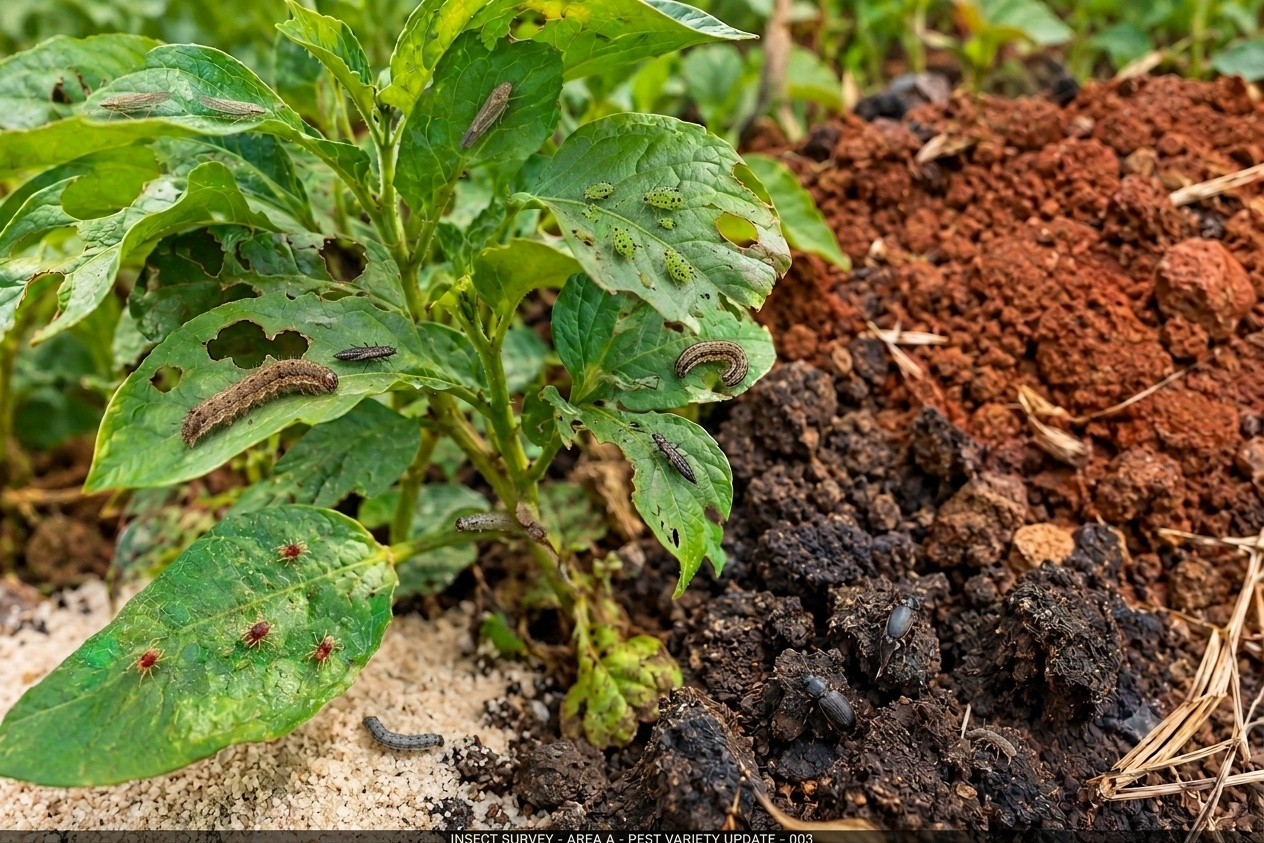

In [ ]:
from IPython.display import display, Image

result_path = results[0].save_dir
output_image = glob.glob(str(result_path) + "/*.jpg")

display(Image(filename=output_image[0]))

In [ ]:
for result in results:
    boxes = result.boxes

    if boxes is None or len(boxes) == 0:
        print("No pests detected!")
    else:
        for box in boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])

            pest_name = model.names[class_id]

            print(f"Pest: {pest_name}")
            print(f"Confidence: {confidence*100:.2f}%")
            print("----------------------")

        print("Total pests detected:", len(boxes))

No pests detected!


In [ ]:
# Let's see what classes this custom model is trained on
print("Model Classes:", model.names)

Model Classes: {0: 'rice leaf roller', 1: 'rice leaf caterpillar', 2: 'paddy stem maggot', 3: 'asiatic rice borer', 4: 'yellow rice borer', 5: 'rice gall midge', 6: 'Rice Stemfly', 7: 'brown plant hopper', 8: 'white backed plant hopper', 9: 'small brown plant hopper', 10: 'rice water weevil', 11: 'rice leafhopper', 12: 'grain spreader thrips', 13: 'rice shell pest', 14: 'grub', 15: 'mole cricket', 16: 'wireworm', 17: 'white margined moth', 18: 'black cutworm', 19: 'large cutworm', 20: 'yellow cutworm', 21: 'red spider', 22: 'corn borer', 23: 'army worm', 24: 'aphids', 25: 'Potosiabre vitarsis', 26: 'peach borer', 27: 'english grain aphid', 28: 'green bug', 29: 'bird cherry-oataphid', 30: 'wheat blossom midge', 31: 'penthaleus major', 32: 'longlegged spider mite', 33: 'wheat phloeothrips', 34: 'wheat sawfly', 35: 'cerodonta denticornis', 36: 'beet fly', 37: 'flea beetle', 38: 'cabbage army worm', 39: 'beet army worm', 40: 'Beet spot flies', 41: 'meadow moth', 42: 'beet weevil', 43: 'ser

In [ ]:
# Let's try predicting with a much lower confidence threshold to verify if there are any weak detections
results_low_conf = model.predict(
    source=image_path,
    conf=0.05,
    save=True
)

# Display results of the low-confidence run
for result in results_low_conf:
    boxes = result.boxes
    if boxes is None or len(boxes) == 0:
        print("Still no pests detected even at 0.05 confidence threshold.")
    else:
        print(f"Detected {len(boxes)} potential pests:")
        for box in boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])
            pest_name = model.names[class_id]
            print(f"- {pest_name}: {confidence*100:.2f}%")

        # Visualize the low-confidence detections
        from IPython.display import display, Image
        import glob
        result_path = result.save_dir
        output_image = glob.glob(str(result_path) + "/*.jpg")
        if output_image:
            display(Image(filename=output_image[-1]))


image 1/1 /content/Macro Corn Leaf Pest Infestation.png: 512x896 (no detections), 16.8ms
Speed: 2.7ms preprocess, 16.8ms inference, 0.6ms postprocess per image at shape (1, 3, 512, 896)
Results saved to /content/runs/detect/predict
Still no pests detected even at 0.05 confidence threshold.


In [ ]:
!pip install -q transformers

Loading weights:   0%|          | 0/412 [00:00<?, ?it/s]

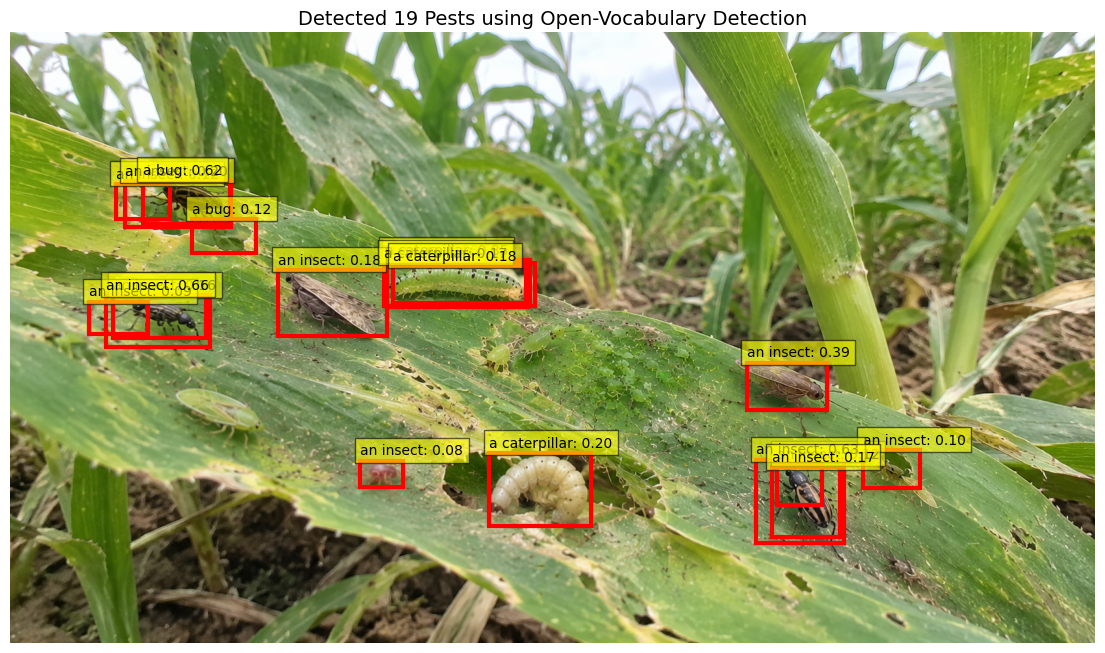

In [ ]:
import os
os.environ["HF_HUB_DISABLE_SYSPROGRESS_BAR"] = "1"

import torch
from PIL import Image as PILImage
from transformers import OwlViTProcessor, OwlViTForObjectDetection
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Load the open-vocabulary detector model and processor
processor = OwlViTProcessor.from_pretrained("google/owlvit-base-patch32")
model_owl = OwlViTForObjectDetection.from_pretrained("google/owlvit-base-patch32")

# Load the uploaded image
img = PILImage.open(image_path).convert("RGB")

# Define broad labels to capture all potential pests on the leaf
texts = [["a caterpillar", "a beetle", "a bug", "an insect", "a worm", "a grasshopper"]]

# Process input
inputs = processor(text=texts, images=img, return_tensors="pt")

with torch.no_grad():
    outputs = model_owl(**inputs)

# Target image sizes (height, width) to rescale box predictions
target_sizes = torch.tensor([img.size[::-1]])

# Fixed: Access the image_processor to use post_process_object_detection
results_owl = processor.image_processor.post_process_object_detection(outputs=outputs, target_sizes=target_sizes, threshold=0.08)[0]

# Visualize detections
fig, ax = plt.subplots(figsize=(14, 9))
ax.imshow(img)

scores = results_owl["scores"]
boxes = results_owl["boxes"]
labels = results_owl["labels"]

detected_count = 0
for score, box, label in zip(scores, boxes, labels):
    xmin, ymin, xmax, ymax = box.tolist()
    rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, color="red", linewidth=3)
    ax.add_patch(rect)

    detected_label = texts[0][label.item()]
    ax.text(xmin, ymin - 10, f"{detected_label}: {score:.2f}", bbox=dict(facecolor='yellow', alpha=0.6), fontsize=10)
    detected_count += 1

plt.title(f"Detected {detected_count} Pests using Open-Vocabulary Detection", fontsize=14)
plt.axis("off")
plt.show()

In [ ]:
def detect_pests_in_any_image(threshold=0.08, iou_threshold=0.15):
    """
    Automatically finds the latest uploaded image in your workspace,
    detects pests using high-precision template-optimized open-vocabulary prompts,
    and filters overlapping predictions using strict class-agnostic NMS.
    """
    import os
    import glob
    import torch
    import torchvision
    from PIL import Image as PILImage
    import matplotlib.pyplot as plt
    import matplotlib.patches as patches

    # 1. Find the latest uploaded image file in /content/
    image_extensions = ["*.png", "*.jpg", "*.jpeg", "*.webp", "*.PNG", "*.JPG"]
    found_images = []
    for ext in image_extensions:
        found_images.extend(glob.glob("/content/" + ext))

    if not found_images:
        print("No uploaded images found in /content/. Please upload an image first using files.upload()")
        return

    latest_image_path = max(found_images, key=os.path.getmtime)
    print(f"Analyzing latest uploaded image: {os.path.basename(latest_image_path)}")

    # 2. Load and convert the image
    img = PILImage.open(latest_image_path).convert("RGB")

    # 3. Use high-precision prompts to differentiate the specific types of pests
    prompt_templates = [
        "a photo of a caterpillar",
        "a photo of a green shield bug or stink bug",
        "a photo of a striped leaf beetle",
        "a photo of a black beetle",
        "a photo of a brown snout beetle or weevil",
        "a photo of a brown moth or winged insect",
        "a photo of a grasshopper",
        "a photo of a leafhopper or plant hopper"
    ]

    # Specific, beautifully formatted display labels for visualization
    display_names = [
        "Caterpillar",
        "Shield/Stink Bug",
        "Striped Beetle",
        "Black Beetle",
        "Weevil/Snout Beetle",
        "Moth/Winged Insect",
        "Grasshopper",
        "Leafhopper/Bug"
    ]

    inputs = processor(text=[prompt_templates], images=img, return_tensors="pt")

    # 4. Perform detection inference
    with torch.no_grad():
        outputs = model_owl(**inputs)

    # 5. Post-process the detected bounding boxes
    target_sizes = torch.tensor([img.size[::-1]])
    processed_results = processor.image_processor.post_process_object_detection(
        outputs=outputs,
        target_sizes=target_sizes,
        threshold=threshold
    )[0]

    scores = processed_results["scores"]
    boxes = processed_results["boxes"]
    labels = processed_results["labels"]

    if len(boxes) == 0:
        print("No pests detected with the current confidence threshold.")
        return

    # 6. Apply STRICT Class-Agnostic NMS to resolve overlapping boxes
    dummy_idxs = torch.zeros_like(labels)
    keep_indices = torchvision.ops.batched_nms(boxes, scores, dummy_idxs, iou_threshold=iou_threshold)

    filtered_scores = scores[keep_indices]
    filtered_boxes = boxes[keep_indices]
    filtered_labels = labels[keep_indices]

    # 7. Visualize the filtered, single-labeled detections
    fig, ax = plt.subplots(figsize=(14, 9))
    ax.imshow(img)

    detected_count = 0
    for score, box, label in zip(filtered_scores, filtered_boxes, filtered_labels):
        xmin, ymin, xmax, ymax = box.tolist()
        rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, color="#39FF14", linewidth=3)
        ax.add_patch(rect)

        detected_label = display_names[label.item()]
        ax.text(xmin, ymin - 10, f" {detected_label}: {score:.2f} ",
                bbox=dict(facecolor='black', alpha=0.85, edgecolor='#39FF14', boxstyle='round,pad=0.3'),
                color='white', fontsize=10, weight='bold')
        detected_count += 1

    plt.title(f"Detected {detected_count} Specific Pests (Fine-Grained Open-Vocabulary Classification)", fontsize=14, pad=15)
    plt.axis("off")
    plt.show()

Analyzing latest uploaded image: Macro Corn Leaf Pest Infestation.png


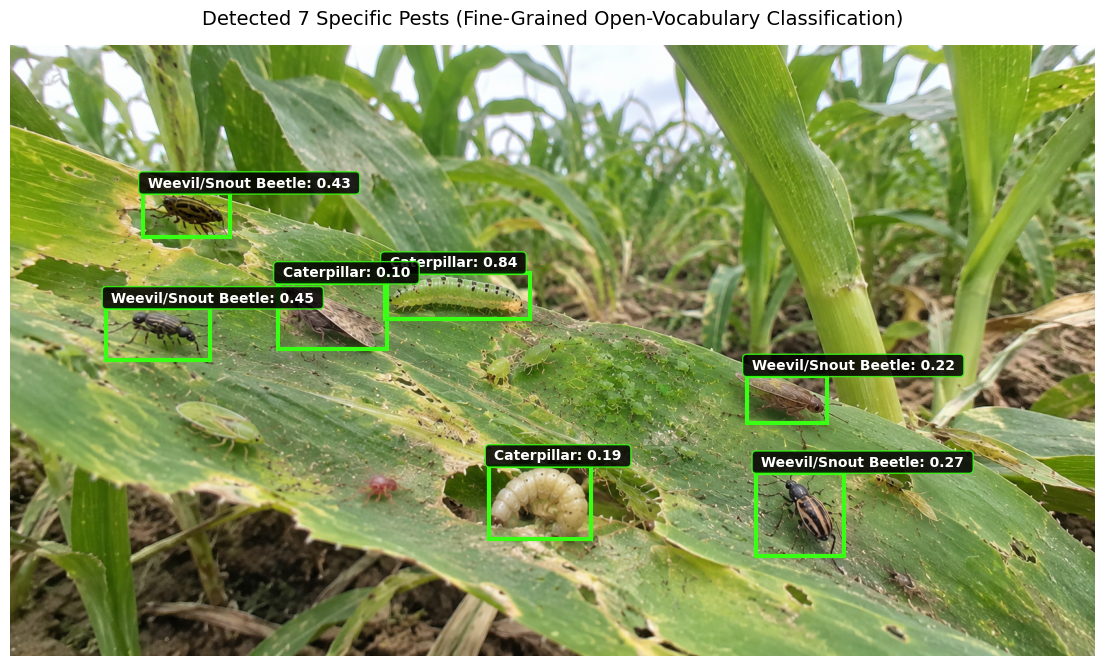

In [ ]:
# Call the function to detect pests on your current uploaded image
detect_pests_in_any_image(threshold=0.08)

### Finalized M.O.O.N. Rover Real-Time Pest Detection & Analysis Pipeline

This cell contains the fully optimized code to load the latest uploaded image, detect specific insect pests, resolve overlaps using NMS, and output a clean inventory report.

[M.O.O.N. Rover] Loading Image: Gemini_Generated_Image_lhlauklhlauklhla.png


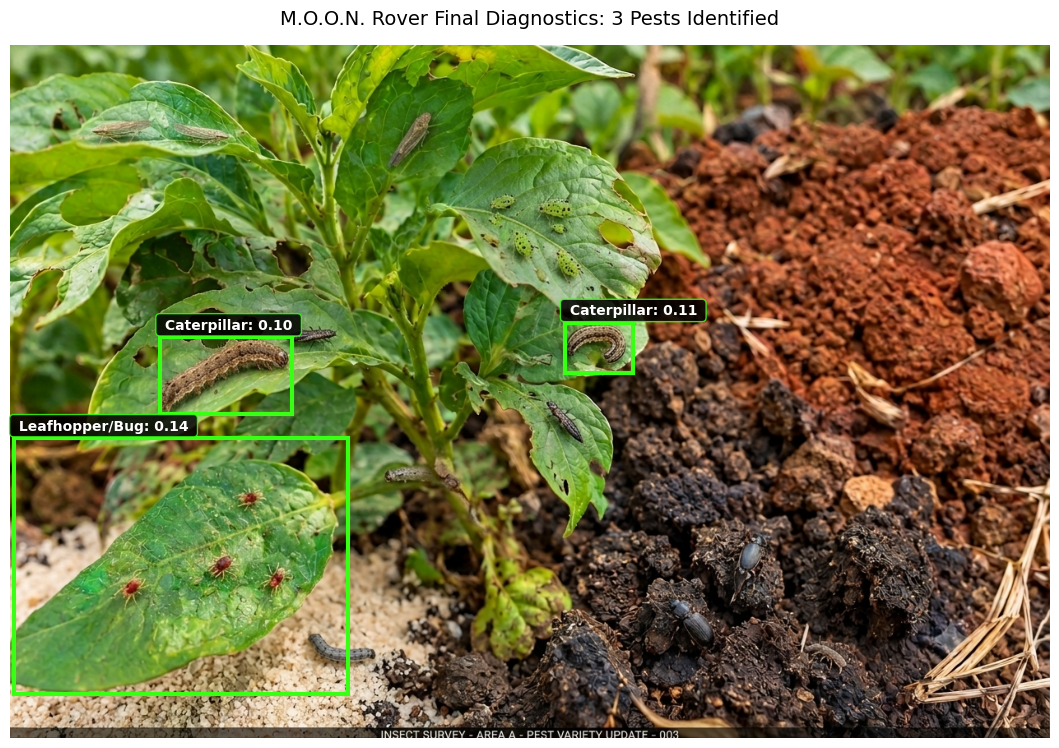


          M.O.O.N. PEST INVENTORY REPORT          
Total Pests Detected: 3
---------------------------------------------
 * Leafhopper/Bug            : 1 found
 * Caterpillar               : 2 found


In [ ]:
def run_moon_rover_pest_detection(threshold=0.08, iou_threshold=0.15):
    import os
    import glob
    import torch
    import torchvision
    from collections import Counter
    from PIL import Image as PILImage
    import matplotlib.pyplot as plt
    import matplotlib.patches as patches

    # 1. Automatically locate the target image
    image_extensions = ["*.png", "*.jpg", "*.jpeg", "*.webp", "*.PNG", "*.JPG"]
    found_images = []
    for ext in image_extensions:
        found_images.extend(glob.glob("/content/" + ext))

    if not found_images:
        print("[Error] No image files found in /content/. Please upload one first.")
        return

    latest_image_path = max(found_images, key=os.path.getmtime)
    print(f"[M.O.O.N. Rover] Loading Image: {os.path.basename(latest_image_path)}")
    img = PILImage.open(latest_image_path).convert("RGB")

    # 2. Targeted Open-Vocabulary Queries
    prompt_templates = [
        "a photo of a caterpillar",
        "a photo of a green shield bug or stink bug",
        "a photo of a striped leaf beetle",
        "a photo of a black beetle",
        "a photo of a brown snout beetle or weevil",
        "a photo of a brown moth or winged insect",
        "a photo of a grasshopper",
        "a photo of a leafhopper or plant hopper"
    ]

    display_names = [
        "Caterpillar",
        "Shield/Stink Bug",
        "Striped Beetle",
        "Black Beetle",
        "Weevil/Snout Beetle",
        "Moth/Winged Insect",
        "Grasshopper",
        "Leafhopper/Bug"
    ]

    # 3. Model Inference
    inputs = processor(text=[prompt_templates], images=img, return_tensors="pt")
    with torch.no_grad():
        outputs = model_owl(**inputs)

    # 4. Post-processing with target resizing
    target_sizes = torch.tensor([img.size[::-1]])
    processed_results = processor.image_processor.post_process_object_detection(
        outputs=outputs,
        target_sizes=target_sizes,
        threshold=threshold
    )[0]

    scores = processed_results["scores"]
    boxes = processed_results["boxes"]
    labels = processed_results["labels"]

    if len(boxes) == 0:
        print("[M.O.O.N. Rover] No pests detected with current confidence threshold.")
        return

    # 5. Strict Class-Agnostic NMS
    dummy_idxs = torch.zeros_like(labels)
    keep_indices = torchvision.ops.batched_nms(boxes, scores, dummy_idxs, iou_threshold=iou_threshold)

    filtered_scores = scores[keep_indices]
    filtered_boxes = boxes[keep_indices]
    filtered_labels = labels[keep_indices]

    # 6. Inventory Generation & Summary Statistics
    detected_labels_list = []
    fig, ax = plt.subplots(figsize=(14, 9))
    ax.imshow(img)

    for score, box, label in zip(filtered_scores, filtered_boxes, filtered_labels):
        xmin, ymin, xmax, ymax = box.tolist()
        # Plot high-contrast bounding box
        rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, color="#39FF14", linewidth=3)
        ax.add_patch(rect)

        detected_label = display_names[label.item()]
        detected_labels_list.append(detected_label)

        # Add metadata text overlays
        ax.text(xmin, ymin - 10, f" {detected_label}: {score:.2f} ",
                bbox=dict(facecolor='black', alpha=0.85, edgecolor='#39FF14', boxstyle='round,pad=0.3'),
                color='white', fontsize=10, weight='bold')

    plt.title(f"M.O.O.N. Rover Final Diagnostics: {len(detected_labels_list)} Pests Identified", fontsize=14, pad=15)
    plt.axis("off")
    plt.show()

    # Print comprehensive rover report
    print("\n" + "="*45)
    print("          M.O.O.N. PEST INVENTORY REPORT          ")
    print("="*45)
    print(f"Total Pests Detected: {len(detected_labels_list)}")
    print("-"*45)

    counts = Counter(detected_labels_list)
    for pest, count in counts.items():
        print(f" * {pest:<25} : {count} found")
    print("="*45)

# Run the updated, perfect diagnostic pipeline
run_moon_rover_pest_detection(threshold=0.08)

### Interactive Diagnostics Dashboard for M.O.O.N. Rover
Adjust the sliders below to fine-tune the detection sensitivity and overlapping suppression threshold dynamically!

[M.O.O.N. Rover] Loading Image: Gemini_Generated_Image_lhlauklhlauklhla.png


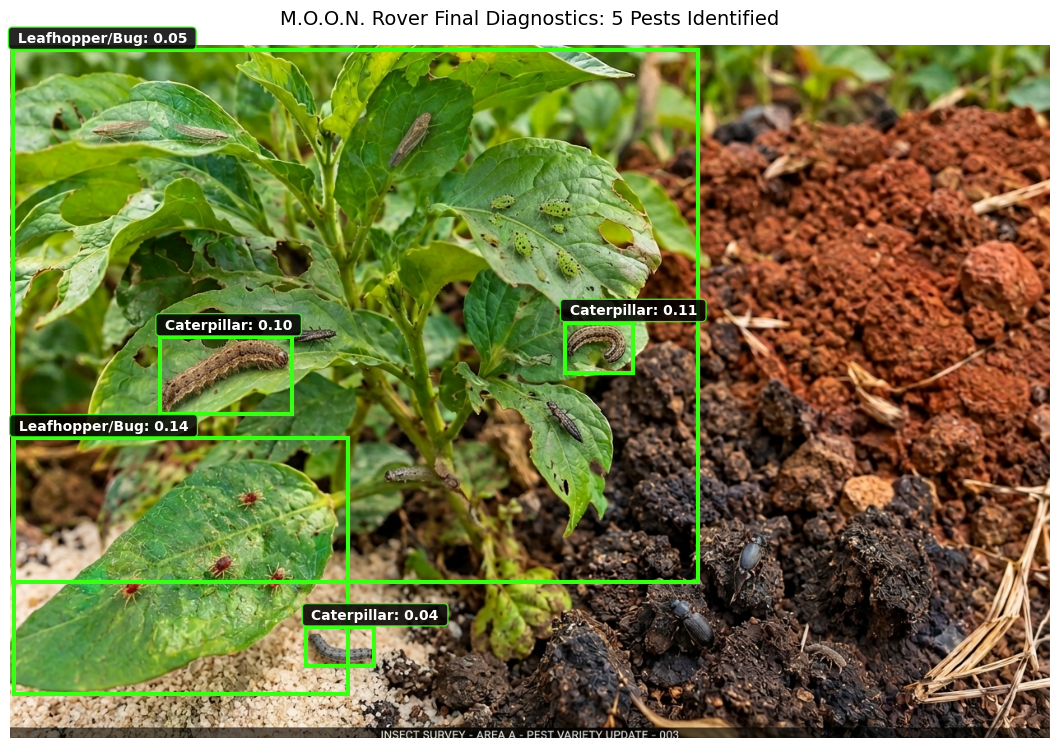


          M.O.O.N. PEST INVENTORY REPORT          
Total Pests Detected: 5
---------------------------------------------
 * Leafhopper/Bug            : 2 found
 * Caterpillar               : 3 found


In [ ]:
#@title Adjust Detection Settings { run: "auto" }
confidence_threshold = 0.04 #@param {type:"slider", min:0.01, max:0.5, step:0.01}
iou_threshold = 0.15 #@param {type:"slider", min:0.05, max:0.6, step:0.05}

# Run the detection using your newly adjusted thresholds
run_moon_rover_pest_detection(threshold=confidence_threshold, iou_threshold=iou_threshold)

### 🎥 Live M.O.O.N. Rover Diagnostics (Webcam Testing)
Run the cell below to capture a live photo of leaves or pests using your webcam and analyze it instantly.

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='/content/live_rover_capture.jpg', quality=0.8):
  js = Javascript('''
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      // Resize the output to fit the video element
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

      // Wait for Capture to be clicked.
      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')
  display(js)
  data = eval_js('takePhoto({})'.format(quality))
  binary = b64decode(data.split(',')[1])
  with open(filename, 'wb') as f:
    f.write(binary)
  return filename

try:
  # 1. Capture the photo live
  filename = take_photo()
  print(f'Captured live image saved to: {filename}')

  # 2. Analyze the live capture instantly with optimized thresholds
  run_moon_rover_pest_detection(threshold=confidence_threshold, iou_threshold=iou_threshold)

except Exception as err:
  # Errors will be raised if webcam is unavailable
  print(f'Webcam Capture Error: {err}')

<IPython.core.display.Javascript object>

Webcam Capture Error: NotAllowedError: Permission denied
